In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Get the colormap
cmap = plt.get_cmap('Set1')

# Number of colors in the colormap
n_colors = cmap.N

# Get RGB values for the colormap
rgb_values = [cmap(i)[:3] for i in range(n_colors)]

# Convert RGB values from 0-1 range to 0-255 range, if needed
rgb_values_255 = [(int(r*255), int(g*255), int(b*255)) for r, g, b in rgb_values]

print("RGB values (0-1 range):")
print(rgb_values)
print("\nRGB values (0-255 range):")
print(rgb_values_255)


RGB values (0-1 range):
[(0.8941176470588236, 0.10196078431372549, 0.10980392156862745), (0.21568627450980393, 0.49411764705882355, 0.7215686274509804), (0.30196078431372547, 0.6862745098039216, 0.2901960784313726), (0.596078431372549, 0.3058823529411765, 0.6392156862745098), (1.0, 0.4980392156862745, 0.0), (1.0, 1.0, 0.2), (0.6509803921568628, 0.33725490196078434, 0.1568627450980392), (0.9686274509803922, 0.5058823529411764, 0.7490196078431373), (0.6, 0.6, 0.6)]

RGB values (0-255 range):
[(228, 26, 28), (55, 126, 184), (77, 175, 74), (152, 78, 163), (255, 127, 0), (255, 255, 51), (166, 86, 40), (247, 129, 191), (153, 153, 153)]


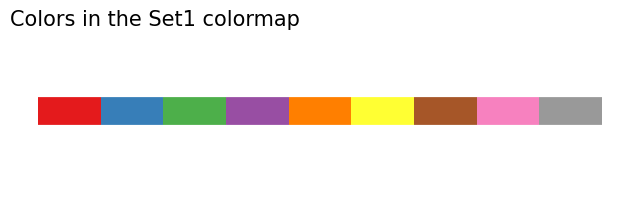

In [2]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def plot_colormap_colors(cmap_name):
    """
    Plots the colors of a given colormap.
    
    Parameters:
    - cmap_name: The name of the colormap as a string.
    """
    # Get the colormap
    cmap = plt.get_cmap(cmap_name)
    
    # Generate a list of indices for each color in the colormap
    cmap_indices = range(cmap.N)
    
    # Generate a list of colors from the colormap
    colors = cmap(cmap_indices)
    
    # Create a figure and a single subplot
    fig, ax = plt.subplots(1, figsize=(8, 2), subplot_kw=dict(xticks=[], yticks=[], frame_on=False))
    ax.set_title(f'Colors in the {cmap_name} colormap', fontsize=15, loc='left')
    
    # Loop through the colors and plot each color as a horizontal line segment
    for i, color in enumerate(colors):
        ax.plot([i, i+1], [1, 1], color=color, solid_capstyle='butt', linewidth=20)
    
    # Remove spines
    for spine in ax.spines.values():
        spine.set_visible(False)
    
    plt.show()

# Example usage
plot_colormap_colors('Set1')


In [4]:
!pip install colorspacious

  Obtaining dependency information for colorspacious from https://files.pythonhosted.org/packages/ab/a1/318b9aeca7b9856410ededa4f52d6f82174d1a41e64bdd70d951e532675a/colorspacious-1.1.2-py2.py3-none-any.whl.metadata

[notice] A new release of pip is available: 23.2.1 -> 24.0
[notice] To update, run: pip install --upgrade pip


In [24]:
import colorspacious
import numpy as np

def find_similar_lightness_colors(gray_value, target_lightness=None):
    """
    Find colors that have the same perceptual lightness as the given gray shade.

    Parameters:
    - gray_value: An integer or float representing the gray shade in sRGB space (0-255 or 0-1 scale).
    - target_lightness: Optional. Specify if you want to match a specific lightness instead of the gray's lightness.

    Returns:
    - A list of colors in RGB space with similar perceptual lightness.
    """
    # Convert the gray shade to RGB (if not already in that format)
    if isinstance(gray_value, (int, float)):
        gray_rgb = [gray_value/255.0, gray_value/255.0, gray_value/255.0]  # Assuming gray_value is in 0-255
    else:
        gray_rgb = gray_value  # Assuming it's already an RGB triplet

    # Convert the gray RGB to CIELAB to find its lightness
    gray_lab = colorspacious.cspace_convert(gray_rgb, "sRGB255", "CIELab")

    if target_lightness is None:
        target_lightness = gray_lab[0]

    # Define a list to hold colors with similar lightness
    similar_lightness_colors = []

    # Generate colors and check their lightness
    for hue in np.linspace(0, 360, num=41):
        for sat in np.linspace(0, 100, num=41):
            # Convert from HSL to RGB
            color_rgb = colorspacious.cspace_convert([hue, sat, target_lightness], "CIELCh", "sRGB255")
            # Check if the conversion is valid (no negative values, all components between 0 and 255)
            if all(0 <= c <= 255 for c in color_rgb):
                similar_lightness_colors.append(np.round(color_rgb/255, 3))

    return similar_lightness_colors

# Example usage
gray_shade = 77   # gray30
similar_colors = find_similar_lightness_colors(gray_shade)

print(f"Found {len(similar_colors)} colors with similar perceptual lightness to gray shade {gray_shade}.")


Found 205 colors with similar perceptual lightness to gray shade 77.


In [25]:
similar_colors

[array([0., 0., 0.]),
 array([0.1, 0.1, 0.1]),
 array([0.113, 0.096, 0.1  ]),
 array([0.126, 0.091, 0.1  ]),
 array([0.138, 0.086, 0.101]),
 array([0.149, 0.08 , 0.101]),
 array([0.16 , 0.074, 0.101]),
 array([0.171, 0.067, 0.101]),
 array([0.181, 0.059, 0.102]),
 array([0.192, 0.049, 0.102]),
 array([0.202, 0.038, 0.102]),
 array([0.212, 0.026, 0.103]),
 array([0.221, 0.013, 0.103]),
 array([0.173, 0.173, 0.173]),
 array([0.187, 0.168, 0.173]),
 array([0.201, 0.163, 0.173]),
 array([0.214, 0.158, 0.173]),
 array([0.227, 0.152, 0.174]),
 array([0.24 , 0.146, 0.174]),
 array([0.252, 0.14 , 0.174]),
 array([0.263, 0.133, 0.174]),
 array([0.275, 0.125, 0.175]),
 array([0.286, 0.116, 0.175]),
 array([0.298, 0.107, 0.175]),
 array([0.309, 0.097, 0.176]),
 array([0.319, 0.085, 0.176]),
 array([0.33 , 0.071, 0.176]),
 array([0.341, 0.054, 0.177]),
 array([0.351, 0.031, 0.177]),
 array([0.362, 0.007, 0.177]),
 array([0.25, 0.25, 0.25]),
 array([0.266, 0.245, 0.25 ]),
 array([0.281, 0.24 , 0.25

<Figure size 600x1200 with 0 Axes>

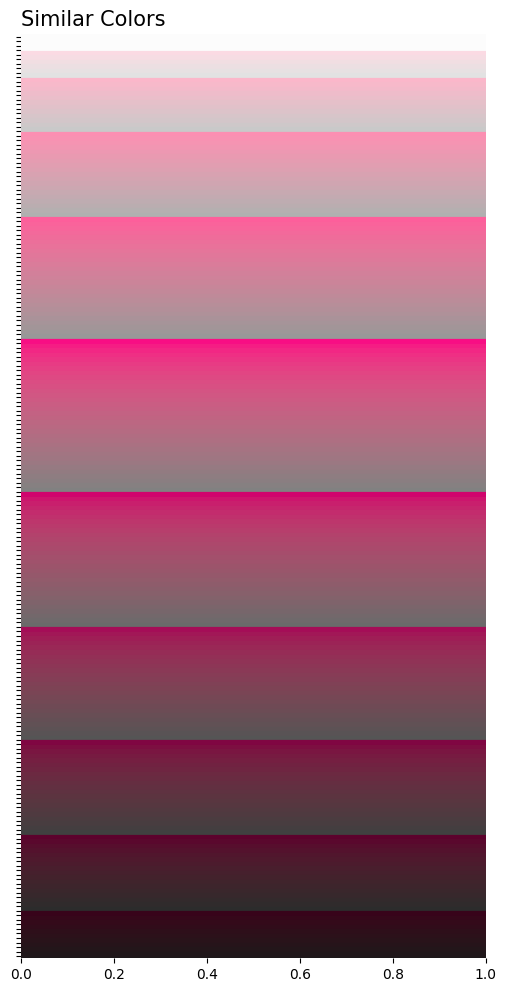

In [29]:
import matplotlib.pyplot as plt

def display_colors(color_list, title='Colors'):
    """
    Display a list of colors using Matplotlib.

    Parameters:
    - color_list: A list of colors in RGB format.
    - title: Optional. Title for the plot.
    """
    num_colors = len(color_list)

    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(6, 12))  # Adjust the figsize as needed

    # Plot each color as a horizontal line
    for i, color in enumerate(color_list):
        color = tuple(color)
        ax.axhline(y=i, color=color, linewidth=20)

    # Set axis limits and labels
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.5, num_colors - 0.5)
    ax.set_yticks(range(num_colors))
    ax.set_yticklabels([''] * num_colors)  # Hide y-axis labels

    # Set plot title
    ax.set_title(title, fontsize=15, loc='left')

    # Remove spines
    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.show()

# Example usage
plt.figure(figsize=(6, 12))
display_colors(similar_colors, title='Similar Colors')


In [31]:
colors = dict(
    Gray20 = (0.162, 0.162, 0.162, 0.7),
    Gray30 = (0.262, 0.262, 0.262, 0.7),
    Gray40 = (0.355, 0.355, 0.355, 0.7),
    Gray50 = (0.44, 0.44, 0.44, 0.7),
    Gray60 = (0.539, 0.539, 0.539, 0.7),
    Gray70 = (0.643, 0.643, 0.643, 0.7),
    Gray80 = (0.757, 0.757, 0.757, 0.7),
    Pu20 = (0.247, 0.0, 0.49, 0.7),
    Pu30 = (0.327, 0.149, 0.559, 0.7),
    Pu40 = (0.395, 0.278, 0.62, 0.7),
    Pu50 = (0.46, 0.406, 0.685, 0.7),
    Pu60 = (0.529, 0.517, 0.742, 0.7),
    Pu70 = (0.636, 0.623, 0.795, 0.7),
    Pu80 = (0.743, 0.747, 0.866, 0.7),
    Bl20 = (0.031, 0.188, 0.42, 0.7),
    Bl30 = (0.031, 0.265, 0.534, 0.7),
    Bl40 = (0.069, 0.365, 0.649, 0.7),
    Bl50 = (0.159, 0.473, 0.725, 0.7),
    Bl60 = (0.271, 0.581, 0.781, 0.7),
    Bl70 = (0.417, 0.681, 0.838, 0.7),
    Bl80 = (0.617, 0.791, 0.882, 0.7),
    Gr20 = (0.0, 0.267, 0.106, 0.7),
    Gr30 = (0.0, 0.312, 0.125, 0.7),
    Gr40 = (0.001, 0.428, 0.173, 0.7),
    Gr50 = (0.112, 0.524, 0.253, 0.7),
    Gr60 = (0.219, 0.633, 0.336, 0.7),
    Gr70 = (0.376, 0.73, 0.424, 0.7),
    Gr80 = (0.574, 0.824, 0.561, 0.7),
    Or20 = (0.498, 0.153, 0.016, 0.7),
    Or30 = (0.498, 0.153, 0.016, 0.7),
    Or40 = (0.599, 0.192, 0.013, 0.7),
    Or50 = (0.746, 0.245, 0.008, 0.7),
    Or60 = (0.887, 0.332, 0.031, 0.7),
    Or70 = (0.966, 0.475, 0.147, 0.7),
    Or80 = (0.992, 0.661, 0.389, 0.7),
    Re20 = (0.404, 0.0, 0.051, 0.7),
    Re30 = (0.495, 0.022, 0.063, 0.7),
    Re40 = (0.662, 0.062, 0.085, 0.7),
    Re50 = (0.806, 0.104, 0.118, 0.7),
    Re60 = (0.939, 0.239, 0.178, 0.7),
    Re70 = (0.985, 0.448, 0.322, 0.7),
    Re80 = (0.988, 0.646, 0.532, 0.7),
)

In [37]:
for name, color in colors.items():
    print(name, list((np.array(color[:3])*255).round().astype(int)))

Gray20 [41, 41, 41]
Gray30 [67, 67, 67]
Gray40 [91, 91, 91]
Gray50 [112, 112, 112]
Gray60 [137, 137, 137]
Gray70 [164, 164, 164]
Gray80 [193, 193, 193]
Pu20 [63, 0, 125]
Pu30 [83, 38, 143]
Pu40 [101, 71, 158]
Pu50 [117, 104, 175]
Pu60 [135, 132, 189]
Pu70 [162, 159, 203]
Pu80 [189, 190, 221]
Bl20 [8, 48, 107]
Bl30 [8, 68, 136]
Bl40 [18, 93, 165]
Bl50 [41, 121, 185]
Bl60 [69, 148, 199]
Bl70 [106, 174, 214]
Bl80 [157, 202, 225]
Gr20 [0, 68, 27]
Gr30 [0, 80, 32]
Gr40 [0, 109, 44]
Gr50 [29, 134, 65]
Gr60 [56, 161, 86]
Gr70 [96, 186, 108]
Gr80 [146, 210, 143]
Or20 [127, 39, 4]
Or30 [127, 39, 4]
Or40 [153, 49, 3]
Or50 [190, 62, 2]
Or60 [226, 85, 8]
Or70 [246, 121, 37]
Or80 [253, 169, 99]
Re20 [103, 0, 13]
Re30 [126, 6, 16]
Re40 [169, 16, 22]
Re50 [206, 27, 30]
Re60 [239, 61, 45]
Re70 [251, 114, 82]
Re80 [252, 165, 136]
